# Figure 12.1 — Mobility, resistivity, and Hall response

Lattice and ionized-impurity scattering set competing mobility limits. Conductivity combines carrier populations. The one-carrier Hall sign identifies charge, while the two-carrier response is weighted by mobility squared.

## Direct NumPy calculation

The governing relations are evaluated explicitly before the reusable course implementation is imported.

300 K mobility at 1e17 cm^-3 = 191.78 cm^2/(V s)
electron Hall coefficient at 1e22 m^-3 = -6.241509e-04 m^3/C
Hall response cancels when p*mu_p^2 = n*mu_n^2


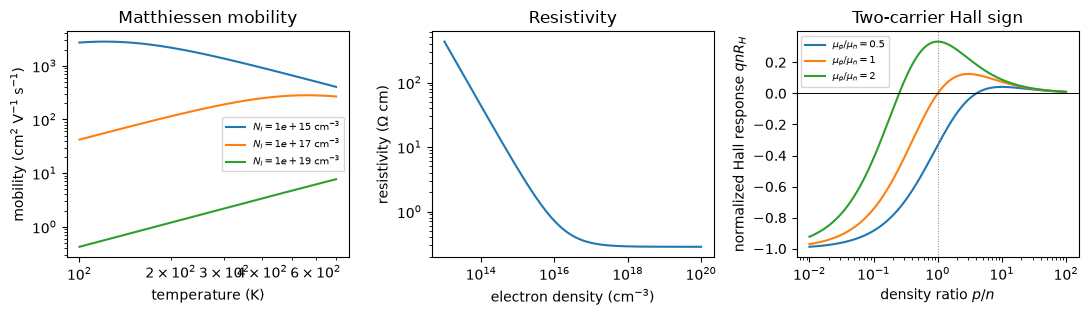

In [1]:
import numpy as np
import matplotlib.pyplot as plt

q = 1.602_176_634e-19
temperature = np.linspace(100.0, 700.0, 500)
impurity_levels = (1.0e15, 1.0e17, 1.0e19)  # cm^-3

fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))

# Opposite temperature powers represent reduced lattice and impurity limits.
for impurity in impurity_levels:
    mu_lattice = 1450.0 * (temperature / 300.0)**-1.5
    mu_impurity = 2200.0 * (temperature / 300.0)**1.5 * (1.0e16 / impurity)
    mobility = 1.0 / (1.0 / mu_lattice + 1.0 / mu_impurity)
    assert np.all(mobility < mu_lattice)
    assert np.all(mobility < mu_impurity)
    axes[0].loglog(temperature, mobility, label=fr"$N_I={impurity:.0e}$ cm$^{{-3}}$")
axes[0].set(xlabel="temperature (K)", ylabel=r"mobility (cm$^2$ V$^{-1}$ s$^{-1}$)", title="Matthiessen mobility")
axes[0].legend(fontsize=7)

# In centimeter units, q*n*mu directly gives conductivity in (ohm cm)^-1.
density_cm3 = np.logspace(13.0, 20.0, 500)
mu_300 = 1.0 / (1.0 / 1450.0 + density_cm3 / (2200.0 * 1.0e16))
resistivity = 1.0 / (q * density_cm3 * mu_300)
axes[1].loglog(density_cm3, resistivity)
axes[1].set(xlabel=r"electron density (cm$^{-3}$)", ylabel=r"resistivity ($\Omega$ cm)", title="Resistivity")

# The two-carrier numerator uses opposite signs and mobility-squared weights.
density_ratio = np.logspace(-2.0, 2.0, 500)  # p/n
n_m3 = np.full_like(density_ratio, 1.0e22)
p_m3 = density_ratio * n_m3
for mobility_ratio in (0.5, 1.0, 2.0):
    mu_n, mu_p = 1.0, mobility_ratio
    hall_coefficient = (p_m3*mu_p**2 - n_m3*mu_n**2) / (
        q * (p_m3*mu_p + n_m3*mu_n)**2
    )
    # q*n removes dimensions and leaves only p/n and mu_p/mu_n.
    axes[2].semilogx(
        density_ratio,
        q*n_m3*hall_coefficient,
        label=fr"$\mu_p/\mu_n={mobility_ratio:g}$",
    )
axes[2].axhline(0.0, color="black", linewidth=0.7)
axes[2].axvline(1.0, color="0.5", linewidth=0.7, linestyle=":")
axes[2].set(xlabel=r"density ratio $p/n$", ylabel=r"normalized Hall response $qnR_H$", title="Two-carrier Hall sign")
axes[2].legend(fontsize=7)

print(f"300 K mobility at 1e17 cm^-3 = {mu_300[np.argmin(abs(density_cm3-1e17))]:.2f} cm^2/(V s)")
print(f"electron Hall coefficient at 1e22 m^-3 = {-1/(q*1e22):.6e} m^3/C")
print("Hall response cancels when p*mu_p^2 = n*mu_n^2")
fig.tight_layout()
plt.show()

## Reusable publication implementation

The tested course implementation writes the deterministic PDF used by the manuscript.

In [2]:
import sys
from pathlib import Path

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "main.tex").exists()
)
sys.path.insert(0, str(ROOT / "figures" / "src"))

from semphy.transport_extensions import mobility_hall_figure

mobility_hall_figure()
print("wrote transport-mobility-hall.pdf")

wrote transport-mobility-hall.pdf
